# Análisis preliminar – TerriData Dimensión 4

## 1. Importación de datos

In [16]:
import pandas as pd

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

df = pd.read_excel('TerriData_Dim4.xlsx')
df.head()

,Código Departamento,Departamento,Código Entidad,Entidad,Dimensión,Subcategoría,Indicador,Dato Numérico,Dato Cualitativo,Año,Mes,Fuente,Unidad de Medida
0,41,Huila,41503,Oporapa,Educación,Acceso a la educación,Cobertura bruta en transición,"47,89",NaN,2005,12,Ministerio de Educación Nacional,Porcentaje (el valor está multiplicado por 100)
1,41,Huila,41518,Paicol,Educación,Acceso a la educación,Cobertura bruta en transición,"55,56",NaN,2005,12,Ministerio de Educación Nacional,Porcentaje (el valor está multiplicado por 100)
2,41,Huila,41524,Palermo,Educación,Acceso a la educación,Cobertura bruta en transición,"67,32",NaN,2005,12,Ministerio de Educación Nacional,Porcentaje (el valor está multiplicado por 100)
3,41,Huila,41530,Palestina,Educación,Acceso a la educación,Cobertura bruta en transición,"63,77",NaN,2005,12,Ministerio de Educación Nacional,Porcentaje (el valor está multiplicado por 100)
4,41,Huila,41548,Pital,Educación,Acceso a la educación,Cobertura bruta en transición,"42,15",NaN,2005,12,Ministerio de Educación Nacional,Porcentaje (el valor está multiplicado por 100)


## 2. Dimensión del dataset

In [17]:
print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')
print(f'Memoria: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB')

pd.DataFrame({
    'tipo': df.dtypes,
    'nulos': df.isna().sum(),
    '% nulos': (df.isna().mean() * 100).round(2),
    'únicos': df.nunique()
})

Filas: 452,990 | Columnas: 13
Memoria: 371.0 MB


,tipo,nulos,% nulos,únicos
Código Departamento,int64,0,0.00,34
Departamento,object,0,0.00,34
Código Entidad,int64,0,0.00,1135
Entidad,object,0,0.00,1045
Dimensión,object,0,0.00,1
Subcategoría,object,0,0.00,5
Indicador,object,0,0.00,37
Dato Numérico,object,36734,8.11,20586
Dato Cualitativo,object,450720,99.50,1
Año,int64,0,0.00,23


## 3. Variables cualitativas

In [18]:
cualitativas = ['Departamento', 'Entidad', 'Dimensión', 'Subcategoría',
                'Indicador', 'Dato Cualitativo', 'Fuente', 'Unidad de Medida']

# Cardinalidad, nulos y categoría más frecuente
pd.DataFrame({
    'únicos': df[cualitativas].nunique(),
    'nulos': df[cualitativas].isna().sum(),
    'moda': df[cualitativas].mode().iloc[0],
    'frec. moda': [df[c].value_counts().iloc[0] for c in cualitativas]
})

,únicos,nulos,moda,frec. moda
Departamento,34,0,Antioquia,49763
Entidad,1045,0,Nariño,1636
Dimensión,1,0,Educación,452990
Subcategoría,5,0,Acceso a la educación,306570
Indicador,37,0,Tasa de deserción intra-anual del sector ofici...,24868
Dato Cualitativo,1,450720,preliminar,2270
Fuente,8,0,Ministerio de Educación Nacional,320414
Unidad de Medida,5,0,Porcentaje (el valor está multiplicado por 100),367638


In [19]:
# Top 10 de cada variable cualitativa
for col in cualitativas:
    print(f'--- {col} ({df[col].nunique()} niveles) ---')
    print(df[col].value_counts(dropna=False).head(10), '')

--- Departamento (34 niveles) ---
Departamento
Antioquia             49763
Boyacá                49400
Cundinamarca          46867
Santander             35062
Nariño                25653
Tolima                19079
Bolívar               18618
Valle del Cauca       17312
Cauca                 17167
Norte de Santander    16341
Name: count, dtype: int64 
--- Entidad (1045 niveles) ---
Entidad
Nariño        1636
Sucre         1635
Bolívar       1635
Córdoba       1635
Villanueva    1620
La Unión      1611
Buenavista    1590
Caldas        1250
Granada       1205
Guadalupe     1195
Name: count, dtype: int64 
--- Dimensión (1 niveles) ---
Dimensión
Educación    452990
Name: count, dtype: int64 
--- Subcategoría (5 niveles) ---
Subcategoría
Acceso a la educación                         306570
Calidad                                        72636
Permanencia y rezago                           65687
Logro                                           7053
Acceso a la educación desagregado por sexo   

### Niveles de la columna Subcategoría

In [20]:
sub = (df['Indicador'].value_counts(dropna=False)
         .rename_axis('Indicador').reset_index(name='registros'))
sub['%'] = (sub['registros'] / len(df) * 100).round(2)
print(f'{len(sub)} niveles')
sub

37 niveles


,Indicador,registros,%
0,Tasa de deserción intra-anual del sector ofici...,24868,5.49
1,Tasa de repitencia del sector oficial en educa...,24856,5.49
2,Cobertura en educación superior,22699,5.01
3,Cobertura neta en educación - Total,22616,4.99
4,Cobertura neta en educación básica,22616,4.99
5,Cobertura neta en transición,22616,4.99
6,Cobertura neta en educación primaria,22616,4.99
7,Cobertura neta en educación secundaria,22616,4.99
8,Cobertura neta en educación media,22616,4.99
9,Cobertura bruta en educación primaria,22615,4.99


## 4. Variables cuantitativas

`Dato Numérico` se lee como texto con formato `1.033.767,00` (punto de miles, coma decimal); se convierte a número antes de describirla.

In [21]:
df['Dato Numérico'] = pd.to_numeric(
    df['Dato Numérico'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False),
    errors='coerce'
)
print('Nulos en Dato Numérico:', df['Dato Numérico'].isna().sum())

cuantitativas = ['Dato Numérico', 'Año', 'Mes']
df[cuantitativas].describe().T

Nulos en Dato Numérico: 36734


,count,mean,std,min,25%,50%,75%,max
Dato Numérico,416256.0,154.436160,7136.450592,0.0,42.3,73.79,95.87,2021985.0
Año,452990.0,2015.307868,5.632196,2003.0,2011.0,2016.00,2020.00,2025.0
Mes,452990.0,11.909799,0.676684,6.0,12.0,12.00,12.00,12.0


In [22]:
# Año y mes son periodos: distribución de registros
print(df['Año'].value_counts().sort_index(), '')
print(df['Mes'].value_counts().sort_index())

Año
2003     2269
2004     2269
2005    17024
2006    17024
2007    17024
2008    17024
2009    17024
2010    19294
2011    19294
2012    19294
2013    19294
2014    20623
2015    25502
2016    25476
2017    25360
2018    34389
2019    27787
2020    27748
2021    27708
2022    27718
2023    21918
2024    20792
2025     1135
Name: count, dtype: int64 
Mes
6       5675
11      6810
12    440505
Name: count, dtype: int64


In [23]:
# Dato Numérico mezcla unidades distintas: describir por unidad de medida
df.groupby('Unidad de Medida')['Dato Numérico'].describe().sort_values('count', ascending=False)

,count,mean,std,min,25%,50%,75%,max
Unidad de Medida,,,,,,,,
Porcentaje (el valor está multiplicado por 100),331335.0,68.699968,40.402880,0.0,41.935,76.55,96.2700,971.92
Porcentaje,45092.0,60.597825,36.593115,0.0,26.570,75.94,95.2325,100.00
Puntos,29476.0,47.526990,4.286948,0.0,44.630,47.56,50.5100,67.67
Numero,10211.0,3661.514935,45427.617805,0.0,207.000,487.00,1150.0000,2021985.00
Años de educación,142.0,8.187183,0.749745,5.0,7.740,8.20,8.6900,10.00


## 5. Series de tiempo por indicador (promedio de todos los municipios)

Cada panel de la grilla 2x2 toma una lista de indicadores; edita `paneles` para cambiar lo que se ve en cada gráfico. El eje Y es el promedio de `Dato Numérico` entre todos los municipios para cada periodo (año-mes). Por defecto se muestran las tasas netas de cobertura.

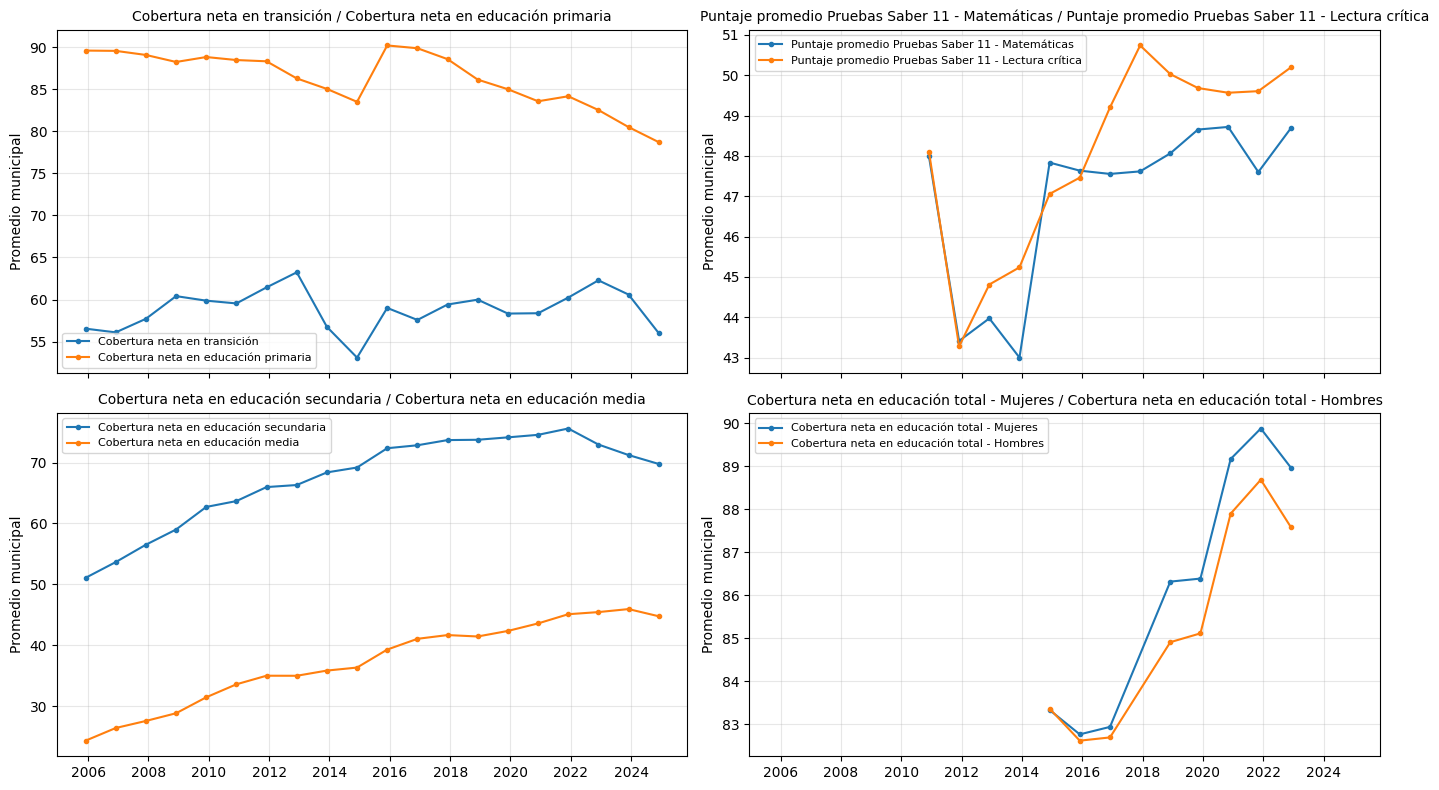

In [26]:
import matplotlib.pyplot as plt

# Lista de indicadores disponibles (para copiar y pegar nombres exactos)
# print(df['Indicador'].unique())

# Un panel por lista: cambia los nombres a mano (pueden ir varios indicadores por panel)
paneles = [
    ['Cobertura neta en transición', 'Cobertura neta en educación primaria'],
    ['Puntaje promedio Pruebas Saber 11 - Matemáticas', 'Puntaje promedio Pruebas Saber 11 - Lectura crítica'],
    ['Cobertura neta en educación secundaria', 'Cobertura neta en educación media'],
    ['Cobertura neta en educación total - Mujeres', 'Cobertura neta en educación total - Hombres'],
]

# Fecha de cada observación y promedio entre municipios por indicador
df['Fecha'] = pd.to_datetime(dict(year=df['Año'], month=df['Mes'], day=1))
promedios = df.groupby(['Indicador', 'Fecha'])['Dato Numérico'].mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, indicadores in zip(axes.flat, paneles):
    for ind in indicadores:
        if ind not in promedios.index.get_level_values('Indicador'):
            print(f'Indicador no encontrado: {ind}')
            continue
        serie = promedios.loc[ind]
        ax.plot(serie.index, serie.values, marker='o', markersize=3, label=ind)
    ax.set_title(' / '.join(indicadores), fontsize=10)
    ax.set_ylabel('Promedio municipal')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

## 6. Cobertura de información por indicador

Para cada indicador se cuentan los departamentos, municipios, años y periodos (año-mes) con al menos un `Dato Numérico` no nulo.

In [25]:
con_dato = df.dropna(subset=['Dato Numérico']).assign(periodo=lambda d: d['Año'] * 100 + d['Mes'])

cobertura = con_dato.groupby('Indicador').agg(
    departamentos=('Código Departamento', 'nunique'),
    municipios=('Código Entidad', 'nunique'),
    años=('Año', 'nunique'),
    meses=('Mes', 'nunique'),
    periodos=('periodo', 'nunique'),
    primer_año=('Año', 'min'),
    último_año=('Año', 'max'),
).sort_values(['municipios', 'años'], ascending=False)

cobertura

,departamentos,municipios,años,meses,periodos,primer_año,último_año
Indicador,,,,,,,
Tasa de deserción intra-anual del sector oficial en educación básica y media (Desde transición hasta once),34,1135,22,1,22,2003,2024
Tasa de repitencia del sector oficial en educación básica y media (Desde transición hasta once),34,1135,22,1,22,2003,2024
Cobertura bruta en educación - Total,34,1135,20,1,20,2005,2024
Cobertura bruta en educación básica,34,1135,20,1,20,2005,2024
Cobertura bruta en educación media,34,1135,20,1,20,2005,2024
Cobertura bruta en educación primaria,34,1135,20,1,20,2005,2024
Cobertura bruta en educación secundaria,34,1135,20,1,20,2005,2024
Cobertura bruta en transición,34,1135,20,1,20,2005,2024
Cobertura en educación superior,34,1135,20,1,20,2005,2024
